# CatalogIQ - Notebook 06: Is this listing good enough to publish?

**The business problem.** Catalog and operations teams cannot look at every listing. Blurry or dark photos, cluttered backgrounds,
text stamped on the picture, a "Blue" shirt shown in red, or missing details all hurt search, conversion and returns. This notebook
builds a **quality checker** that gives every listing a 0-100 score, says exactly what is wrong in plain English, and produces a
report an operations team could turn into a dashboard.

**How to read it.** Every step says WHAT we did, WHY it matters to the business and WHAT WE LEARNED. Numbers in the "learned" boxes were
printed by the code above them. All logic is in `src/catalogiq/quality/`; heavy computations are run once by scripts in `scripts/`
and this notebook reads their saved results.

**Honest scope.** The catalog photos are 60x80 pixel studio shots, almost all of them clean. Real defects are therefore rare, so we
**create** defects (blurred, darkened, cluttered, watermarked copies) to measure how well each check finds them, and we say clearly
where a number comes from a copy and where it comes from a real photo. All labels in this phase were made by the AI assistant, not a
person (the owner chose this), so they are provisional.

In [1]:
import json, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catalogiq.config import get_quality_config, resolve_path
from catalogiq.quality import degrade
from catalogiq.quality.completeness import completeness, required_attributes
from catalogiq.quality.evaluate import CHECK_FOR_TYPE, per_check_scores, recall_by_level
from catalogiq.quality.image_checks import load_thresholds
from catalogiq.quality.score import listing_score

pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 160)
cfg = get_quality_config()
OUT = resolve_path(cfg["paths"]["eval_dir"]); FIG = resolve_path("reports/figures")
images = np.load(resolve_path(cfg["paths"]["image_cache"]), mmap_mode="r")
index = pd.read_parquet(resolve_path(cfg["paths"]["image_index"]))
print("catalog photos:", len(index), "| size of every photo (height, width):", images.shape[1:3])
print("split sizes:", index["split"].value_counts().to_dict())

catalog photos: 42257 | size of every photo (height, width): (80, 60)
split sizes: {'train': 29579, 'test': 6339, 'val': 6339}


## 1. What the catalog photos look like, and how we create defects

**What we did.** Every photo in the catalog is the same tiny 60x80 studio shot. To test the checks we make **degraded copies** of good photos:
blurred (3 strengths), darkened (3), washed out by too much light (3), shrunk (3), squeezed or stretched (3), pasted onto a busy background,
and with a text banner or a see-through watermark. Each defect type has levels, so we can report whether mild problems are caught as well as
severe ones. Milder levels (for example a barely visible blur) are shown but **not counted as defects**, because a seller should not be nagged about them.

**Why.** Without real defective photos there is no other way to know whether a check works. A check that cannot find a deliberately damaged
photo will certainly not find a naturally damaged one.

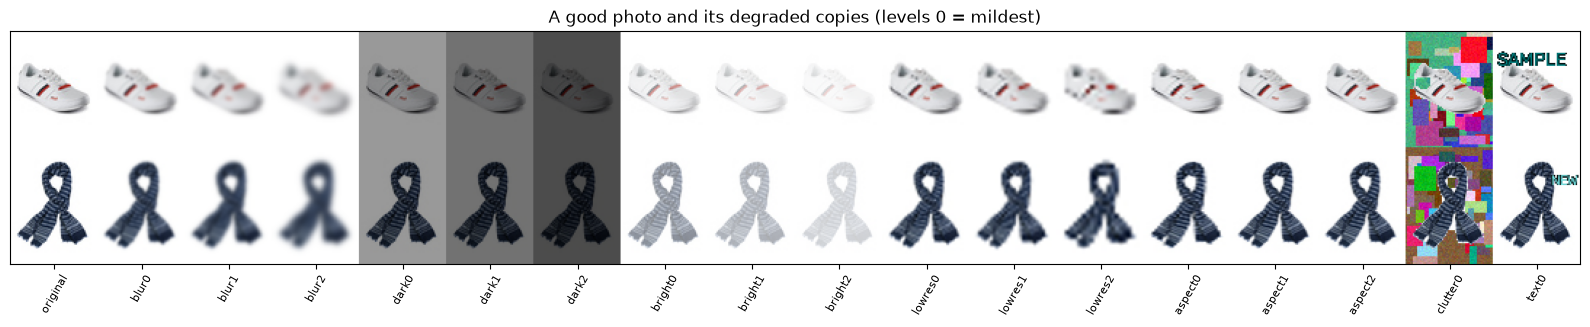

In [2]:
rng = np.random.default_rng(3)
val = np.where(index["split"].eq("val"))[0]
sample = np.asarray(images[rng.choice(val, 2, replace=False)])
cols, titles = [], ["original"]
rows = []
for k, img in enumerate(sample):
    parts = [img]
    for i, t, lv, out in degrade.make_degraded_set(img[None], rng):
        parts.append(np.array(__import__("PIL.Image", fromlist=["Image"]).fromarray(out).resize((60, 80))))
        if k == 0: titles.append(f"{t}{lv}")
    rows.append(np.hstack(parts))
fig, ax = plt.subplots(figsize=(16, 3.6))
ax.imshow(np.vstack(rows)); ax.set_xticks([30 + 60 * i for i in range(len(titles))]); ax.set_xticklabels(titles, rotation=60, fontsize=8)
ax.set_yticks([]); ax.set_title("A good photo and its degraded copies (levels 0 = mildest)")
plt.tight_layout(); plt.savefig(FIG / "26_degradations.png", dpi=120); plt.show()

**What we learned:** The copies look like what sellers upload: soft focus, dim rooms, glare, a thumbnail, a squeezed picture, a messy room behind the
product and a stamped banner. The aspect-ratio copies and the shrunk copies are real resolution changes (the shrunk copy is a smaller picture, not a blurred one).

## 2. The six image checks and how their thresholds were chosen

**What we did.** Each check is a plain number measured by OpenCV, compared with a threshold:
| Check | The measure | Flag when |
|---|---|---|
| Blurry | variance of the Laplacian (how much sharp edge detail there is) | too low |
| Too dark | average brightness | too low |
| Overexposed / washed out | brightness of the darkest 5% of pixels | too high |
| Low resolution | short side in pixels | under 48 px (this catalog is 60x80; a live marketplace would use at least 500) |
| Bad aspect ratio | width / height | outside 0.55 to 1.45 |
| Cluttered background | colour spread in the four corner patches (a product sits in the middle, so a clean photo has plain corners) | too high |
| Text or watermark | CLIP zero-shot: "text overlaid" vs "clean product photo" | score too high |

**How thresholds were chosen (rule fixed before looking at results).** On the *validation* photos, pick for each measure the threshold with
the highest recall on real defects that still flags **at most 3% of clean photos**. Rationale: a false alarm wastes a seller's time and
erodes trust, so we limit them first. Resolution and aspect ratio are rules, not tuned. The test photos were never used for tuning.

**A hand-labelled sample.** The brief asks to tune on a small hand-labelled sample. We labelled 120 natural validation photos (60 random + 60 from the
extremes of each measure, shown without scores). The honest result is below.

In [3]:
lab = pd.read_csv(OUT / "image_labels.csv")
print("labelled photos:", len(lab), "| defects found by eye:", lab[["blurry","too_dark","overexposed","cluttered_background","text_or_watermark"]].sum().to_dict())
tr = pd.DataFrame(json.loads((OUT / "tuning_report.json").read_text())).T
print(tr.to_string())
print()
print("tuned thresholds in use:", load_thresholds())

labelled photos: 120 | defects found by eye: {'blurry': 0, 'too_dark': 0, 'overexposed': 0, 'cluttered_background': 2, 'text_or_watermark': 0}
                        threshold  recall_val  fpr_val   n_pos  n_neg
blur_min_laplacian_var   259.4879       1.000    0.028  1560.0  898.0
dark_max_mean_luma       117.6396       1.000    0.001  1560.0  898.0
bright_min_p5_luma       230.8000       0.126    0.028  1560.0  898.0
clutter_max_corner_std    37.4095       0.413    0.029   782.0  898.0
text_min_clip_margin       1.5686       0.591    0.029   780.0  898.0

tuned thresholds in use: {'blur_min_laplacian_var': 259.4879, 'dark_max_mean_luma': 117.6396, 'bright_min_p5_luma': 230.8, 'min_short_side_px': 48, 'aspect_min': 0.55, 'aspect_max': 1.45, 'clutter_max_corner_std': 37.4095, 'text_min_clip_margin': 1.5686}


**What we learned:** Of 120 natural photos, only 2 had a real defect that we could see (both cluttered lifestyle backgrounds: a mirror scene and a
bedroom scene); none was blurry, dark, washed out or carried overlaid text. This is the main finding about the data: **the catalog is almost defect-free**, so the labelled
sample can only guard against false alarms and the degraded copies must carry the tuning. On validation the tuned thresholds catch every
blurred and darkened copy (recall 1.00, with 2.8% and 0.1% of clean photos flagged), 59% of text overlays, 41% of cluttered backgrounds, but only 13% of washed-out copies.
The labels are the AI assistant's and are provisional.

### Why text uses CLIP and clutter uses corners (two failed first attempts)
We first measured text with a simple blob heuristic and clutter with the colour spread of a border band. Both failed, and we show it, because
"simple" was the brief's preference and the evidence overrules it.

In [4]:
tv = pd.read_csv(OUT / "tuning_val.csv")
clean = tv[tv["kind"] == "clean"]
txt = tv[(tv["kind"] == "degraded") & (tv["type"] == "text")]
thr = np.percentile(clean["text_chars"], 97)
print(f"text: blob heuristic flags >{thr:.0f} text-like blobs in a row -> recall {(txt['text_chars'] > thr).mean():.1%} at about 3% false alarms")
thr = np.percentile(clean["text_margin"], 97)
print(f"text: CLIP zero-shot                              -> recall {(txt['text_margin'] > thr).mean():.1%} at about 3% false alarms")
print("clutter: border-band edge/colour measures were tried first: recall 0.9% - 2.6% at the same false-alarm cap (see decisions.md);")
cl = tv[(tv["kind"] == "degraded") & (tv["type"] == "clutter")]
thr = np.percentile(clean["corner_std"], 97)
print(f"clutter: corner colour spread                     -> recall {(cl['corner_std'] > thr).mean():.1%} at about 3% false alarms")

text: blob heuristic flags >3 text-like blobs in a row -> recall 1.4% at about 3% false alarms
text: CLIP zero-shot                              -> recall 59.4% at about 3% false alarms
clutter: border-band edge/colour measures were tried first: recall 0.9% - 2.6% at the same false-alarm cap (see decisions.md);
clutter: corner colour spread                     -> recall 52.1% at about 3% false alarms


**What we learned:** The blob heuristic finds about 1% of overlaid text at a 3% false-alarm rate, while CLIP (which can read text even in a 60x80 picture) finds
about 59%. For clutter, looking at the photo border failed because models and products cross the border, so clean photos looked busy; looking at the four *corners* works
because a product rarely fills all four (52% here; 41% at the stricter threshold actually used, which also had to keep the hard natural photos in the labelled sample unflagged). These first-attempt numbers (border band) come from the first tuning run and are recorded in `docs/decisions.md`, not recomputed here.

## 3. Do the checks work? Test results on photos they have never seen

**What we did.** 500 clean test photos and 8,500 degraded copies of them (17 per photo). For each check: **recall** = the share of real
defects it finds, **precision** = the share of its flags that are right. Precision here is strict: a photo that is *dark* and also gets a
"blurry" flag counts that "blurry" flag as wrong, even though a dark, low-contrast photo really is hard to see. The column
`false_alarm_rate_clean` is the fairest single number for a seller: the share of **clean** photos wrongly flagged.

                      precision  recall     f1  false_alarm_rate_clean    tp    fp   fn
check                                                                                  
blurry                    0.423   0.999  0.595                   0.024   999  1360    1
too_dark                  0.899   1.000  0.947                   0.002  1000   112    0
overexposed               0.646   0.115  0.195                   0.012   115    63  885
low_resolution            0.667   1.000  0.800                   0.000  1000   500    0
bad_aspect_ratio          1.000   1.000  1.000                   0.000  1500     0    0
cluttered_background      0.746   0.452  0.563                   0.010   226    77  274
text_or_watermark         0.387   0.604  0.472                   0.026   302   478  198



recall by severity level (level 0 = mildest; mild levels are not counted as defects):
level                                 0     1     2
aspect  ->  bad_aspect_ratio       1.00  1.00  1.00
blur  ->  blurry                   0.47  1.00  1.00
bright  ->  overexposed            0.04  0.06  0.17
clutter  ->  cluttered_background  0.45   NaN   NaN
dark  ->  too_dark                 0.23  1.00  1.00
lowres  ->  low_resolution         1.00  1.00  1.00
text  ->  text_or_watermark        0.60   NaN   NaN

blurry: flags by photo type -> {'blur': 1232, 'bright': 797, 'dark': 490, 'aspect': 44, 'lowres': 17}
too_dark: flags by photo type -> {'dark': 1114, 'clutter': 101, 'blur': 3, 'lowres': 3, 'aspect': 3}
text_or_watermark: flags by photo type -> {'text': 302, 'dark': 197, 'clutter': 172, 'lowres': 33, 'aspect': 30}


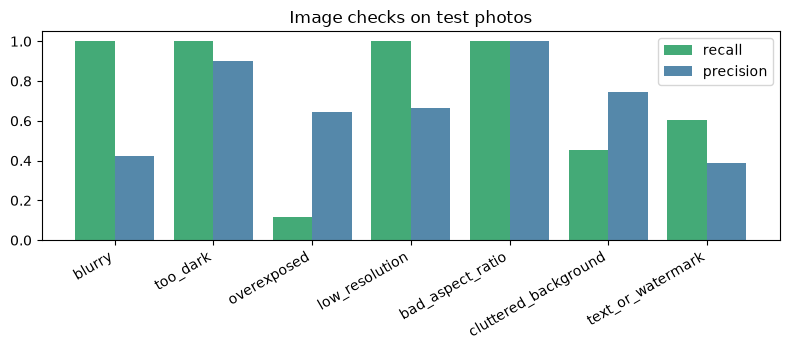

In [5]:
d = pd.read_csv(OUT / "image_eval_flags.csv")
scores = per_check_scores(d)
print(scores[["precision", "recall", "f1", "false_alarm_rate_clean", "tp", "fp", "fn"]].round(3).to_string())
print()
lv = recall_by_level(d).pivot(index="type", columns="level", values="recall").round(2)
lv.index = [f"{t}  ->  {CHECK_FOR_TYPE[t]}" for t in lv.index]
print("recall by severity level (level 0 = mildest; mild levels are not counted as defects):")
print(lv.to_string())
print()
for c in ["blurry", "too_dark", "text_or_watermark"]:
    sub = d[d[c]]
    kinds = sub.assign(k=np.where(sub.kind == "clean", "clean", sub["type"])).k.value_counts().head(5).to_dict()
    print(f"{c}: flags by photo type -> {kinds}")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(scores)); ax.bar(x - 0.2, scores["recall"], 0.4, label="recall", color="#4a7"); ax.bar(x + 0.2, scores["precision"], 0.4, label="precision", color="#58a")
ax.set_xticks(x); ax.set_xticklabels(scores.index, rotation=30, ha="right"); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title("Image checks on test photos")
plt.tight_layout(); plt.savefig(FIG / "27_image_checks_test.png", dpi=120); plt.show()

**What we learned:** *Aspect ratio* is perfect (a rule). *Too dark* and *blurry* find essentially every defect they were built for (recall 1.00 and 0.999) and flag only
0.2% and 2.4% of clean photos. *Low resolution* finds all shrunk photos. *Cluttered background* is useful but incomplete (recall 0.45, precision 0.75). *Text* finds 60% of overlays, but with 2.6% false alarms on clean
photos. *Overexposure is weak*: recall is 0.115 overall and only 0.17 even for the strongest washed-out copies, because a white product on a white background looks "overexposed" to any simple measure.
The low precision of *blurry* (0.42) is not mostly about clean photos: it fires on the strongly washed-out and the dark copies, because low contrast gives low edge detail. The text check fires on cluttered and dark copies too (busy pictures look like text to CLIP).
Mild defects (blur at level 0, darkness at level 0) are caught about half and a quarter of the time, which is deliberate. Next step: normalise the blur measure by contrast.

## 4. Does the photo match the listing? (image-text consistency)

**What we did.** For each listing's **colour, product type and gender**, two checks read only the photo:
- the **Phase 2 classifier** must be confident that the photo shows a *different* value than the listing says;
- **CLIP zero-shot** gives a probability to every value ("a product photo of a red coloured item") and the best alternative must beat the stated value by a margin.

We tested four ways of combining them (classifier alone, CLIP alone, either, both). To measure detection we **injected 300 mismatches** (100 wrong colours that are
not look-alikes such as Blue vs Navy, 100 product types from another sub-category, 100 Men-Women swaps) into the stated attributes of the validation split to tune and into the test split to report.
Precision is measured against the injected rows only: a listing whose *real* catalog label is wrong counts as a false alarm, so these numbers are a **lower bound**.

In [6]:
C = json.loads((OUT / "consistency_eval.json").read_text())
print("chosen on validation:", C["chosen"], "| validation F1:", round(C["val_f1"], 3))
print()
print("test split, by attribute (300 injected mismatches in 6,339 listings):")
print(pd.DataFrame(C["test"]).T[["precision", "recall", "f1", "tp", "fp", "fn"]].round(2).to_string())
print()
print("test split, the four ways to combine the signals (each tuned on validation):")
print(pd.DataFrame(C["test_variants"]).T[["min_conf", "margin", "precision", "recall", "f1", "fp"]].round(2).to_string())
print("\nlistings flagged although nothing was injected:", C["natural_flags"])

chosen on validation: {'min_conf': 0.9, 'margin': 0.4, 'mode': 'and'} | validation F1: 0.521

test split, by attribute (300 injected mismatches in 6,339 listings):
             precision  recall    f1     tp     fp     fn
baseColour        0.25    0.21  0.23   21.0   62.0   79.0
articleType       0.51    0.56  0.53   56.0   54.0   44.0
gender            0.60    0.66  0.63   66.0   44.0   34.0
overall           0.47    0.48  0.47  143.0  160.0  157.0

test split, the four ways to combine the signals (each tuned on validation):
      min_conf  margin  precision  recall    f1     fp
clf       0.95    0.50       0.53    0.42  0.47  112.0
clip      0.50    0.90       0.20    0.43  0.27  527.0
or        0.95    0.95       0.30    0.55  0.39  389.0
and       0.90    0.40       0.47    0.48  0.47  160.0

listings flagged although nothing was injected: {'total': 151, 'by_attribute': {'baseColour': 59, 'articleType': 50, 'gender': 42}, 'n_test': 6339}


**What we learned:** Overall the chosen rule (classifier at least 90% sure **and** CLIP margin at least 0.4) found 143 of the 300 injected mismatches (recall 0.48) with precision 0.47. By attribute:
**gender is easiest** (F1 0.63), **product type middling** (0.53), **colour hardest** (0.23, recall 0.21). Colour is hard for good reasons: the classifier is only 67.5% accurate on colour, shades blend into
neighbouring families, and Phase 1 found 44% disagreement between twin photos of the same product. The two signals together (F1 0.47) are *no better* than the classifier alone (0.47) with a similar precision/recall trade-off,
and CLIP alone is poor (precision 0.20, F1 0.27); the combination mainly trades recall for fewer false alarms. We kept it because it is the brief's design and it is more stable on validation, not because it clearly wins.

### Are the "false alarms" really false?
160 flags landed on listings we did not alter. The catalog itself contains wrong labels, so some of these may be the checker doing its job. We reviewed 24 of them by eye (8 per attribute); the reviewer is the AI assistant, thumbnails are tiny, so this is indicative only.

{'ambiguous_boundary': 12, 'likely_label_error': 12}
review_verdict  ambiguous_boundary  likely_label_error
attribute                                             
articleType                      4                   4
baseColour                       3                   5
gender                           5                   3


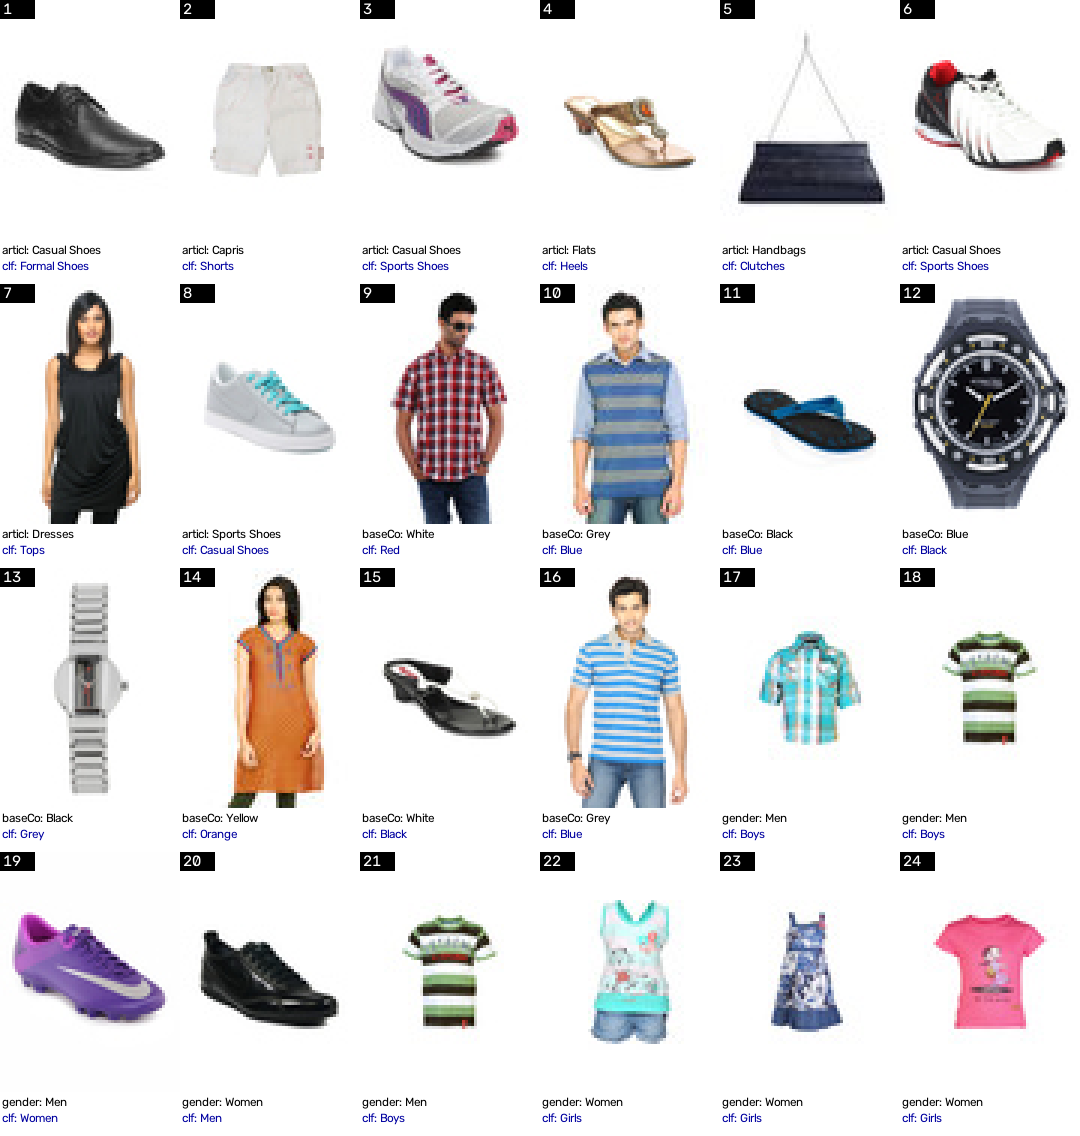

In [7]:
from IPython.display import Image as IPImage, display
key = pd.read_csv(OUT / "natural_flags_review_key.csv")
print(key["review_verdict"].value_counts().to_dict())
print(key.groupby(["attribute", "review_verdict"]).size().unstack(fill_value=0))
display(IPImage(filename=str(OUT / "natural_flags_review.png"), width=900))

**What we learned:** Of 24 flagged listings we had not touched, **none had a clearly correct label**: 12 looked like real catalog errors (a heeled sandal listed as Flats, a silver watch listed as Black, an orange dress listed as Yellow, children's clothes listed as Women)
and 12 were ambiguous boundaries (Casual vs Sports shoes, Men vs Boys). So the strict precision of 0.47 understates how useful the flags are: if the half-and-half pattern held, roughly 80 of the 160 "false alarms" would be real errors.
We do **not** call this a measured precision; it is a 24-listing indication.

## 5. Completeness

**What we did.** Each product type belongs to a category (the same rules as Phase 4), and each category lists required attributes in `configs/rag.yaml` (for example gender, product type and colour for watches). Completeness is the share of required
attributes present (plus the product name). Missing, blank and placeholder values such as "Unknown" count as missing.

In [8]:
test = pd.read_parquet(resolve_path("data/processed/fashion_test.parquet"))
comp = [completeness(r) for r in test.to_dict("records")]
print("test catalog mean completeness:", round(np.mean([c["pct"] for c in comp]), 2), "% | listings below 100%:", sum(c["pct"] < 100 for c in comp))
rng = np.random.default_rng(0)
hits = 0
for r in rng.choice(test.to_dict("records"), 300, replace=False):
    _, req = required_attributes(r["articleType"]); gone = req[int(rng.integers(len(req)))]
    hits += gone in completeness({**r, gone: None})["missing"]
print("injected one missing required attribute into 300 listings -> found", hits, "of 300")
print(pd.DataFrame({g: [", ".join(required_attributes(a)[1])] for g, a in [("watches", "Watches"), ("topwear", "Shirts"), ("footwear", "Casual Shoes"), ("other", "Zzz")]}, index=["required"]).T.to_string())

test catalog mean completeness: 100.0 % | listings below 100%: 0


injected one missing required attribute into 300 listings -> found 300 of 300
                                                            required
watches          gender, articleType, baseColour, productDisplayName
topwear   gender, articleType, baseColour, usage, productDisplayName
footwear  gender, articleType, baseColour, usage, productDisplayName
other                                articleType, productDisplayName


**What we learned:** The test catalog is 100% complete (Phase 1 cleaning removed or filled every required field), so on this data completeness cannot flag anything; it matters for new seller uploads. We checked the logic itself by blanking one required field in 300 listings: all 300 were found.
This is a test of the code, not a measurement of real sellers, whose gaps will be common.

## 6. The listing quality score, with fixes

**What we did.** `score = 40% image quality + 35% consistency + 25% completeness`, each 0-100. Image quality starts at 100 and loses points per raised check (blurry 40, too dark 40, low resolution 50, overexposed 30, cluttered 25, text 25, aspect 20); consistency loses 60 per mismatching
attribute; completeness is the percentage of required fields. Weights and penalties are in `configs/quality.yaml`, reasons in `docs/decisions.md`. Every flag carries a fix in plain English ("Retake the photo in better light"). A listing below 85 "needs attention".

In [9]:
imgcols = ["blurry", "too_dark", "overexposed", "low_resolution", "bad_aspect_ratio", "cluttered_background", "text_or_watermark"]
def img_score(row):
    return listing_score([c for c in imgcols if row[c]], [], 100.0, [])["score"]
d["score"] = d.apply(img_score, axis=1)
print("mean score of CLEAN test photos:", round(d.loc[d.kind == "clean", "score"].mean(), 1))
tab = d[d.kind == "degraded"].groupby(["type", "level"])["score"].mean().round(1).unstack()
print("mean score of degraded copies (type x level):"); print(tab.to_string())
from sklearn.metrics import roc_auc_score
y = (d.kind == "degraded") & (d.apply(lambda r: r["level"] >= cfg["degrade"]["positive_from_level"].get(r["type"], 9) if r["kind"] == "degraded" else False, axis=1))
print("AUC (score separates real-defect copies from clean photos):", round(roc_auc_score(y[d.kind.isin(["clean"]) | y], -d.loc[d.kind.isin(["clean"]) | y, "score"]), 3))
ex = listing_score(["blurry", "overexposed"], [{"attribute": "baseColour", "stated": "Blue", "seen": "Red"}], 75.0, ["usage"])
print("\nexample listing:", ex["score"], ex["components"], "needs_attention:", ex["needs_attention"])
for f in ex["flags"]: print(" -", f["area"], "|", f["message"], "->", f["fix"])

mean score of CLEAN test photos: 99.1
mean score of degraded copies (type x level):
level       0     1     2
type                     
aspect   71.5  90.8  91.0
blur     92.2  83.8  83.7
bright   97.4  91.2  82.2
clutter  88.8   NaN   NaN
dark     93.9  79.6  71.3
lowres   79.1  79.4  79.7
text     93.3   NaN   NaN


AUC (score separates real-defect copies from clean photos): 0.925

example listing: 44.8 {'image': 30.0, 'consistency': 40.0, 'completeness': 75.0} needs_attention: True
 - image | blurry -> Retake the photo with a steady hand or a tripod and tap to focus on the product.
 - image | overexposed -> Retake the photo with less light or flash; the picture is washed out.
 - consistency | baseColour listed as Blue but the photo looks like Red -> The photo does not match the listing (listed Blue, photo looks like Red). Check the baseColour or replace the photo.
 - completeness | missing: usage -> Add the missing details: usage.


**What we learned:** Clean test photos average 99.1 (not 100, because about 1 in 100 gets a false flag). Real-defect copies score lower: strongly darkened 79.6 and 71.3, shrunk about 79, blurred about 84, squeezed or stretched 71.5 to 91 and
strongly washed-out only 82.2 because the overexposure check misses most of them. Mild copies barely move the score (blur level 0 is 92.2). Because the image component carries 40% of the weight, one flag alone costs 8 to 21 points: a blurry or too-dark photo gives 84, low resolution 80 and a mismatch 79, all under the 85 line, while cluttered background or text alone gives 90, overexposure 88 and a bad aspect ratio 92, which stay above it.
The score separates real-defect copies from clean photos with an AUC of 0.925. The weights are judgement, not learned: they say "a mismatch between photo and listing is as serious as a ruined photo". Nothing here was fitted to returns or sales data, because the catalog has none.

## 7. The batch report: the whole test catalog

**What we did.** `scripts/run_quality_report.py` ran every check on all 6,339 test listings and wrote `reports/phase6/quality_report.csv` (one row per listing: score, issues, fix text, raw measures) and `quality_summary.json`. This is the data an operations dashboard would read.

{'pct_with_any_issue': 8.31, 'pct_needs_attention': 4.12, 'score_mean': 98.67} | listings: 6339
issue types: {'text_or_watermark': 171, 'blurry': 104, 'overexposed': 84, 'cluttered_background': 64, 'mismatch_baseColour': 63, 'mismatch_articleType': 55, 'mismatch_gender': 44, 'too_dark': 3}
                      n  pct_with_issue  mean_score
jewellery         146.0           46.58       91.36
watches           381.0           16.54       98.09
innerwear_socks   410.0           14.88       97.84
beauty            277.0           10.83       98.10
topwear          1930.0            9.02       98.71
accessories       233.0            7.30       98.54
bags_wallets      557.0            5.92       99.03
footwear         1375.0            3.93       99.17
dresses_ethnic    496.0            3.43       99.35
bottomwear        372.0            2.69       99.44
eyewear           162.0            0.00      100.00



jewellery (146 listings): flagged blurry 22.6 %, overexposed 38.4 %; median darkest-5% brightness 217 vs 66 catalog-wide
watches (381 listings): flagged text 14.4 %


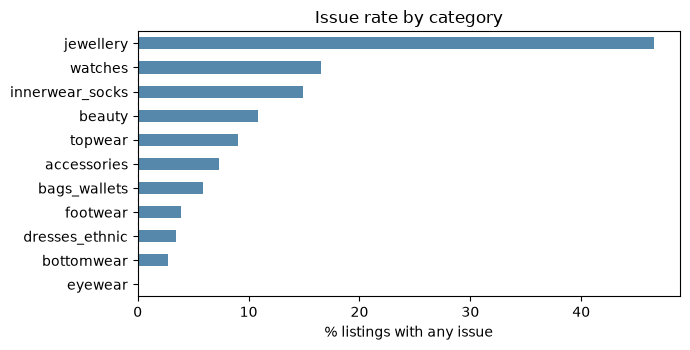


        id articleType  score        image_issues   mismatches                                                                                                                                                     fixes
24   35322    Earrings   72.0  blurry;overexposed               Retake the photo with a steady hand or a tripod and tap to focus on the product. | Retake the photo with less light or flash; the picture is washed out.
184  28639     Tshirts   84.0              blurry                                                                                       Retake the photo with a steady hand or a tripod and tap to focus on the product.
195  10804  Flip Flops   79.0                      articleType                            The photo does not match the listing (listed Flip Flops, photo looks like Shirts). Check the articleType or replace the photo.
203  58115     Pendant   72.0  blurry;overexposed               Retake the photo with a steady hand or a tripod and tap to focus on

In [10]:
S = json.loads((OUT / "quality_summary.json").read_text())
print({k: round(S[k], 2) for k in ["pct_with_any_issue", "pct_needs_attention", "score_mean"]}, "| listings:", S["n_listings"])
print("issue types:", S["issue_counts"])
bg = pd.DataFrame(S["by_group"]).T.sort_values("pct_with_issue", ascending=False)
print(bg.to_string())
rep = pd.read_csv(OUT / "quality_report.csv").fillna("")
jew = rep[rep.group == "jewellery"]
print("\njewellery (146 listings): flagged blurry", round(100 * jew.image_issues.str.contains("blurry").mean(), 1), "%, overexposed", round(100 * jew.image_issues.str.contains("overexposed").mean(), 1), "%;",
      "median darkest-5% brightness", int(jew.metric_p5_luma.median()), "vs", int(rep.metric_p5_luma.median()), "catalog-wide")
wat = rep[rep.group == "watches"]
print("watches (381 listings): flagged text", round(100 * wat.image_issues.str.contains("text").mean(), 1), "%")
fig, ax = plt.subplots(figsize=(7, 3.6)); bg["pct_with_issue"].plot.barh(ax=ax, color="#58a"); ax.invert_yaxis(); ax.set_xlabel("% listings with any issue"); ax.set_title("Issue rate by category")
plt.tight_layout(); plt.savefig(FIG / "28_issue_rate_by_category.png", dpi=120); plt.show()
print(); print(rep.loc[rep.needs_attention.astype(str).eq("True"), ["id", "articleType", "score", "image_issues", "mismatches", "fixes"]].head(5).to_string())

**What we learned:** 8.3% of the 6,339 test listings carry at least one flag and 4.1% score below 85 (mean score 98.7). The most common flags are text or watermark (171), blurry (104), overexposed (84) and cluttered background (64); 162 listings have a photo-listing mismatch (63 colour, 55 product type, 44 gender), and only 3 are too dark.
**Most of these flags are probably not real photo problems.** By category, jewellery shows 46.6% with an issue: these are tiny items on a mostly white canvas, so the darkest 5% of pixels is almost white (median 217 against 66 catalog-wide) and the check calls 38% of them "overexposed" and 23% "blurry".
Watches are flagged for text 14% of the time because dials and logos look like text to CLIP. With thresholds set on all categories at once, **small, bright or text-bearing products are over-flagged**. Per-category thresholds are the first thing we would fix before showing this to an operations team.

## 8. What this means, and what we would do next

**Conclusions.**
1. **The catalog photos are almost defect-free**, so defects had to be created to be measured: blur and darkness are found almost perfectly, resolution and aspect ratio trivially, clutter and text partly, overexposure poorly.
2. **Simple rules were not enough for text, and border statistics were not enough for clutter.** Both were replaced after measuring (CLIP for text; corner patches for clutter), and the failed first attempts are recorded.
3. **Photo-listing mismatch detection is useful but modest** (precision 0.47, recall 0.48 against injected errors; colour is weakest). The flags it raises on untouched listings looked like real catalog errors or boundary cases in a 24-listing review, so it is a good *review queue* but not a way to auto-reject listings.
4. **One set of thresholds does not fit every category.** Jewellery and watches are over-flagged for reasons that have nothing to do with photo quality.

**Limits to keep in mind.**
- All photos are 60x80 studio shots; the studio-to-phone-camera gap noted in Phase 1 is still unmeasured. The 48-pixel resolution rule suits this catalog, not a live marketplace (use 500 pixels).
- Defect detection is measured on copies we made, which are cleaner and more extreme than real seller mistakes. Mild real defects may be missed.
- Every label (120 natural photos, the 24-listing review) is the AI assistant's. The injected mismatches are exact, the natural flags are judged by eye.
- Score weights are judgement, not fitted to outcomes; there is no returns or conversion data.
- Blur depends on contrast, so dark or washed-out photos also trigger it; the consistency check's colour part is limited by noisy colour labels.

**Next steps.** Thresholds per category; contrast-normalised blur; a real-seller photo sample (phone photos) to measure the domain gap; replace the AI labels with the owner's; show scores, flags and fixes in the Streamlit app and expose them through the API.